In [1]:
!pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 3.0 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/10.9 MB 3.0 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/10.9 MB 2.9 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/10.9 MB 2.7 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/10.9 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.9 MB 2.7 MB/s eta 0:00:03
   -------------- ------------------------- 3.9/10.9 MB 2.8 MB/s eta 0:00:03
   ---------------- ----------------------- 4.5/10.9 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 5.0/10.9 MB 2.8 MB/s eta 0:00:03
   --------------------- ------------------ 5.8/10.9 MB 2.8 MB/s eta 0:00:02
   ----------------------- ---------------- 6.3/10.9 MB 2.8 MB/s eta 0:00:02
   ------------------------- -------------- 6.8/10.9 MB 2.8 MB/s eta 0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import pandas as pd

df = pd.read_csv(r'C:\Users\MF\Downloads\archive\retail_sales_dataset.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [13]:
df.info()

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [14]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


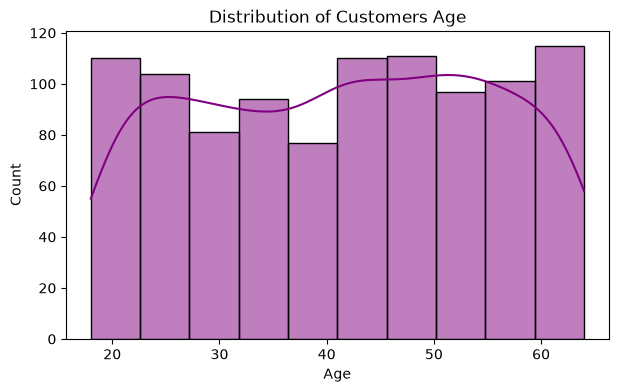

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.histplot(df['Age'], bins=10, kde=True, color='purple')
plt.title('Distribution of Customers Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

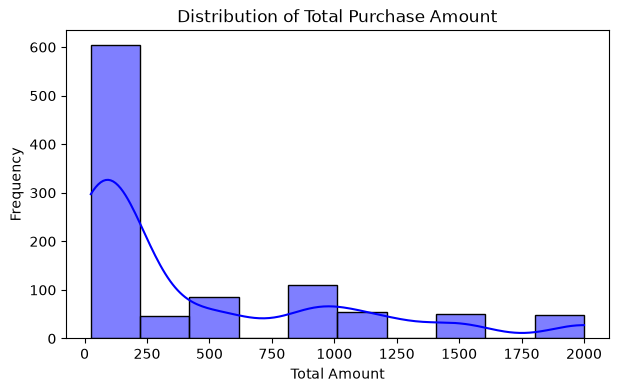

In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(df['Total Amount'], bins=10, kde=True, color='Blue')
plt.title('Distribution of Total Purchase Amount')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')
plt.show()

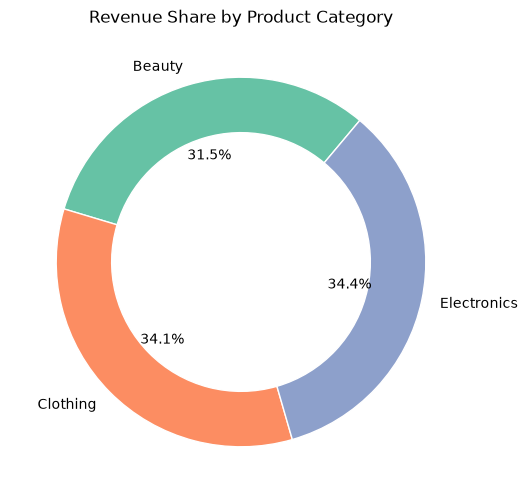

In [24]:
category_revenue = df.groupby('Product Category')['Total Amount'].sum()


plt.figure(figsize=(6, 6))
plt.pie(category_revenue, labels=category_revenue.index, autopct='%1.1f%%', 
        colors=sns.color_palette('Set2'), startangle=50, 
        wedgeprops=dict(width=0.3, edgecolor='w')) 

plt.title('Revenue Share by Product Category')
plt.show()

   Gender  Total Amount
0  Female        232840
1    Male        223160


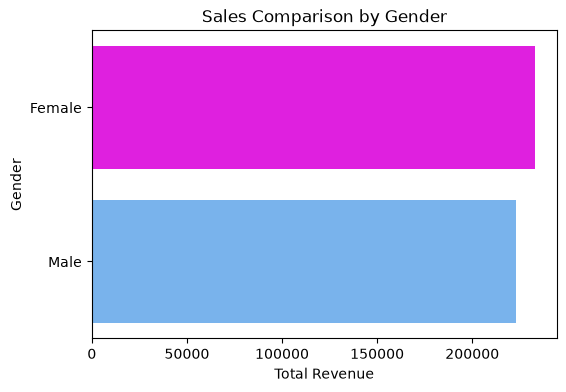

In [27]:
gender_sales = df.groupby('Gender')['Total Amount'].sum().reset_index()
print(gender_sales)

plt.figure(figsize=(6, 4))
sns.barplot(data=gender_sales, y='Gender', x='Total Amount', palette=['#ff00ff', '#66b3ff'], hue='Gender', legend=False)

plt.title('Sales Comparison by Gender')
plt.xlabel('Total Revenue')
plt.ylabel('Gender')
plt.show()

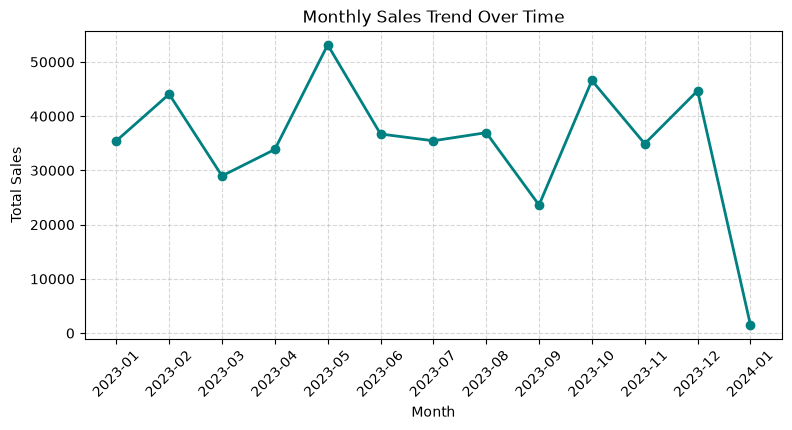

In [28]:
df['Date'] = pd.to_datetime(df['Date'])
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Date'].astype(str)

plt.figure(figsize=(9, 4))
plt.plot(monthly_sales['Date'], monthly_sales['Total Amount'], marker='o', color='teal', linewidth=2)

plt.title('Monthly Sales Trend Over Time')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()